# Elliptic envelope

Elliptic Envelope is an unsupervised anomaly-detection algorithm that assumes the normal data follows a roughly Gaussian distribution and fits an ellipse around the normal observations. Points falling outside the learned ellipse are considered anomalies.

# For more info click the link below 

https://docs.google.com/document/d/1pbYG_Bo79mQNJ9GLqjlm5Qu8kJEvZJhdhJ2y6BsxoP4/edit?usp=sharing

# Notes and interview Q and answer

https://docs.google.com/document/d/1jNm233i_KG5aTagJbJ154GNWA2_T45woKEN9bLD2i4k/edit?usp=sharing

# Coding

# Dataset 

In [2]:
import numpy as np                                      # Numerical calculations
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import make_blobs                 # Generate Gaussian-like clustered data
from sklearn.covariance import EllipticEnvelope         # Elliptic Envelope anomaly detector

# Generate normal data

In [3]:
X_normal, _ = make_blobs(
    n_samples=500,                                      # Generate 500 normal observations
    centers=1,                                          # Create one main cluster
    cluster_std=1.5,                                    # Control the spread of the normal cluster
    random_state=42                                     # Make the dataset reproducible
)

print("Normal data shape:", X_normal.shape)             # 500 samples × 2 features

Normal data shape: (500, 2)


# Add anomalies 

In [4]:
anomalies = np.array([
    [8, 8],                                             # Artificial anomaly
    [9, 7],                                             # Artificial anomaly
    [-8, 8],                                            # Artificial anomaly
    [-7, -8],                                           # Artificial anomaly
    [8, -7]                                             # Artificial anomaly
])

In [5]:
# Combine them 


X = np.vstack([
    X_normal,                                            # Normal observations
    anomalies                                             # Add artificial anomalies
])

print("Final data shape:", X.shape)                     # 505 samples × 2 features


Final data shape: (505, 2)


# Visualize the data 

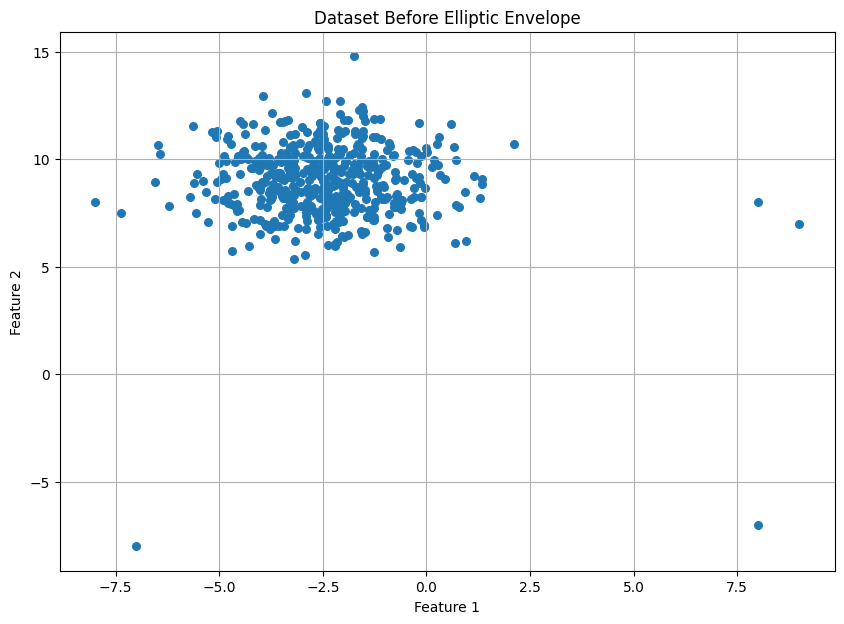

In [6]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                             # First feature
    X[:, 1],                                             # Second feature
    s=30                                                 # Point size
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Dataset Before Elliptic Envelope")

plt.grid()
plt.show()

# Create elliptic envelope 



In [8]:
elliptic_model = EllipticEnvelope(
    contamination=0.01,                                  # Expect approximately 1% of observations to be anomalies
    random_state=42                                     # Make the result reproducible
)

# Fit the model 

In [9]:
elliptic_model = EllipticEnvelope(
    contamination=0.01,                                  # Expect approximately 1% of observations to be anomalies
    random_state=42                                     # Make the result reproducible
)

# Fit the model 

In [12]:
elliptic_model.fit(
    X                                                     # Learn the distribution of the observations
)

EllipticEnvelope(contamination=0.01, random_state=42)

# Predict anomalies 

In [13]:
predictions = elliptic_model.predict(X)

print(predictions[:20])

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


# Extract anomalies 

In [14]:
anomaly_mask = predictions == -1                         # Create a Boolean mask for detected anomalies

X_anomalies = X[
    anomaly_mask                                         # Extract observations classified as anomalies
]

print("Detected anomalies:", len(X_anomalies))           # Count detected anomalies

Detected anomalies: 6


# Visualize the result 

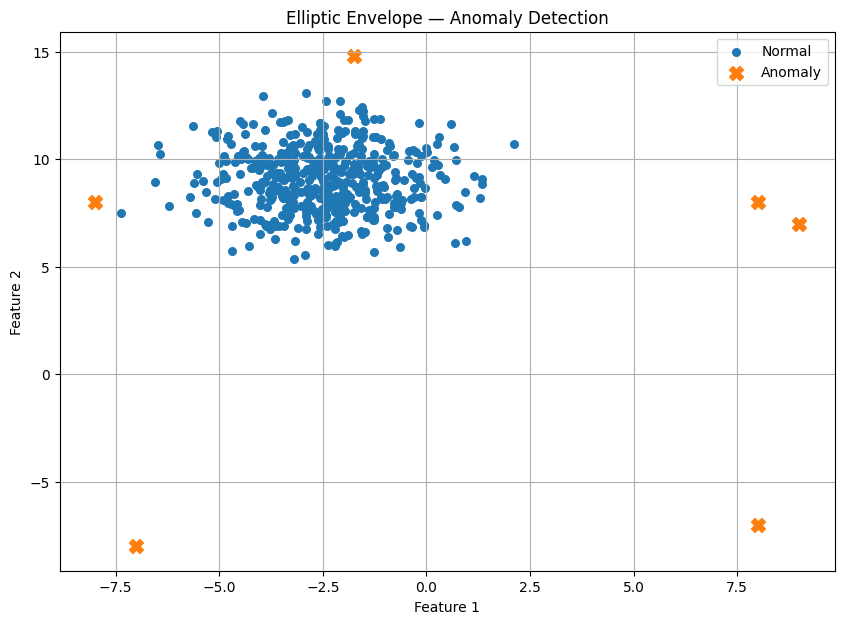

In [15]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                             # First feature
    X[:, 1],                                             # Second feature
    s=30,                                                # Normal point size
    label="Normal"
)

plt.scatter(
    X_anomalies[:, 0],                                   # First feature of detected anomalies
    X_anomalies[:, 1],                                   # Second feature of detected anomalies
    s=100,                                               # Make anomalies larger
    marker="X",                                          # Use X marker for anomalies
    label="Anomaly"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Elliptic Envelope — Anomaly Detection")

plt.legend()
plt.grid()
plt.show()

# Experimet with contamination 

In [17]:
for contamination in [0.01, 0.02, 0.05, 0.10]:

    model = EllipticEnvelope(
        contamination=contamination,                    # Change the expected anomaly proportion
        random_state=42                                 # Keep results reproducible
    )

    model.fit(
        X                                                 # Learn the normal-data distribution
    )

    predictions = model.predict(
        X                                                 # Detect anomalies
    )

    print(
        f"contamination={contamination} → anomalies={sum(predictions == -1)}"
    )

contamination=0.01 → anomalies=6
contamination=0.02 → anomalies=11
contamination=0.05 → anomalies=26
contamination=0.1 → anomalies=51


# Complate code of elliptic envelope 

Total observations: 505
Detected anomalies: 6


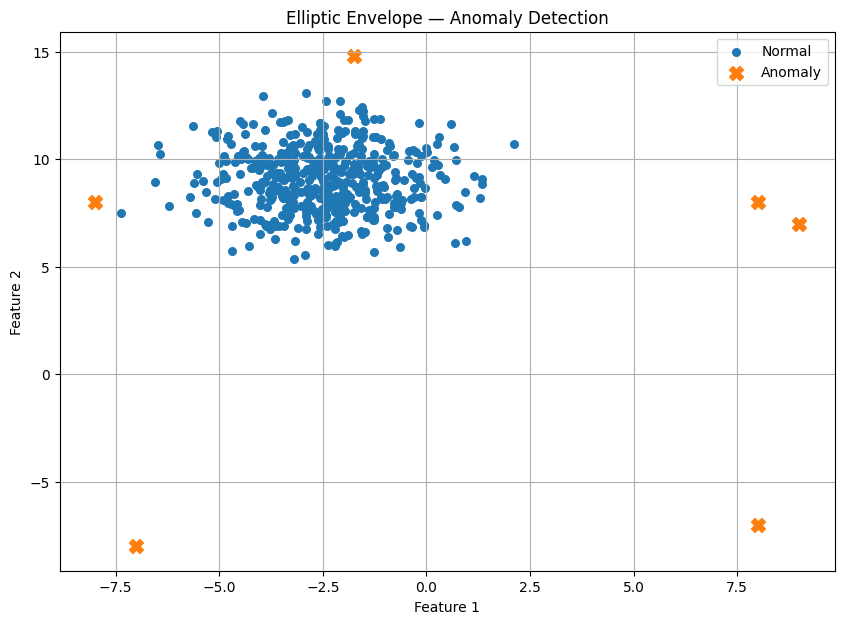

In [18]:
import numpy as np                                      # Numerical calculations
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import make_blobs                 # Generate Gaussian-like clustered data
from sklearn.covariance import EllipticEnvelope         # Elliptic Envelope anomaly detector


X_normal, _ = make_blobs(
    n_samples=500,                                      # Generate 500 normal observations
    centers=1,                                          # Create one normal cluster
    cluster_std=1.5,                                    # Control cluster spread
    random_state=42                                     # Make the dataset reproducible
)


anomalies = np.array([
    [8, 8],                                             # Artificial anomaly
    [9, 7],                                             # Artificial anomaly
    [-8, 8],                                            # Artificial anomaly
    [-7, -8],                                           # Artificial anomaly
    [8, -7]                                             # Artificial anomaly
])


X = np.vstack([
    X_normal,                                           # Normal observations
    anomalies                                            # Add artificial anomalies
])


elliptic_model = EllipticEnvelope(
    contamination=0.01,                                  # Expect approximately 1% anomalies
    random_state=42                                     # Reproducible result
)


elliptic_model.fit(
    X                                                     # Learn the normal data distribution
)


predictions = elliptic_model.predict(
    X                                                     # Detect normal observations and anomalies
)


anomaly_mask = predictions == -1                         # Identify detected anomalies

X_anomalies = X[
    anomaly_mask                                         # Extract detected anomalies
]


print("Total observations:", len(X))                    # Total number of observations
print("Detected anomalies:", len(X_anomalies))          # Number of detected anomalies


plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                             # First feature
    X[:, 1],                                             # Second feature
    s=30,                                                # Normal point size
    label="Normal"
)

plt.scatter(
    X_anomalies[:, 0],                                   # Anomaly feature 1
    X_anomalies[:, 1],                                   # Anomaly feature 2
    s=100,                                               # Larger anomaly markers
    marker="X",                                          # X marker
    label="Anomaly"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Elliptic Envelope — Anomaly Detection")

plt.legend()
plt.grid()
plt.show()